In [17]:
import os, csv
import json
import geass
import pickle
import pandas as pd
import networkx as nx
from collections import Counter
from rdkit import Chem
from rdkit.Chem.PandasTools import LoadSDF
from IPython.display import clear_output
from constants import REACTIONS, REACTANTS, FILLING_ATOMS, BROKEN_BONDS, BROKEN_BONDS_LIPIDS

print('Networkx version :', nx.__version__)

Networkx version : 2.2


# 1. Loading molecules libraries

In [2]:
# Load the UCL (Unknown Compound Library)
'''
UCL is a dict with the following format:
{
    "UC_XXXX": rdkit mol of the compound
}
'''
if os.path.isfile('data/UCL.pkl'):
    with open('data/UCL.pkl', 'rb') as f:
        UCL = pickle.load(f)
else:
    UCL = {}

In [3]:
# Load the BUL (Biological unit library) or Natural products library
with open('../recap-delivery/data/BUL_names.pkl', 'rb') as f:
    BULnames = pickle.load(f)

In [4]:
# Load the BUL (Biological unit library) or Natural products library
# with open('../recap-delivery/data/BUL_names.pkl', 'rb') as f:
with open('data/BUL_with_lipids.pkl', 'rb') as f:
    BULnames_lipids = pickle.load(f)

In [5]:
# Loads the PBU

with open('metadisassembler5/data/PBU_v2.pkl', 'rb') as f:
    PBU = pickle.load(f)

In [6]:
# Loads the BUL

with open('metadisassembler5/data/BUL_Mar23.pkl', 'rb') as f:
    BUL = pickle.load(f)

In [7]:
with open('backups/lipid_mols.pkl', 'rb') as output_file:
    lipid_mols = pickle.load(output_file)

In [3]:
# Load the ACTUAL SECRETed 1853 molecules
sdf_filename = 'data/SECRETed_space_Feb23.sdf'
df_complete = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule', strictParsing=True)
df_smiles = df_complete[['ID','SMILES', 'Molecule']]
df_aux_ids = pd.read_csv('data/id_smiles_Feb23.csv', index_col=0)
df_smiles['IDs'] = df_aux_ids['IDs']

/home/ubuntu/anaconda3/envs/map4_test2/lib/python3.7/site-packages/ipykernel_launcher.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


In [8]:
df_complete = pd.read_csv('data/Database3_no_SS.csv')

In [9]:
df_complete['Molecule'] = df_complete.apply(lambda x: Chem.MolFromSmiles(x['Isomeric_SMILES']), axis=1)

In [10]:
df_complete.rename({'Isomeric_SMILES':'SMILES'}, axis=1, inplace=True)
df_complete.rename({'ID_unique':'IDs'}, axis=1, inplace=True)
df_smiles = df_complete[['IDs','SMILES', 'Molecule']]

In [10]:
# Assign the SECRETed molecules to the collection
mols = list(df_smiles['Molecule'])
# This indexer will help us to control the molecules
indexer_original_mols = list(df_smiles['IDs'])

NameError: name 'df_smiles' is not defined

In [14]:
df_peptides = pd.read_csv('peptides_filtered.csv')

In [15]:
df_peptides['Molecule'] = df_peptides.apply(lambda x: Chem.MolFromSmiles(x['SMILES']), axis=1)

In [16]:
peptide_mols = list(df_peptides['Molecule'])
peptide_names = list(df_peptides['Id'])

## 1.1. Remove the modifications from the NP database

In [ ]:
# The modifications in the NP database are not needed.

print('Size before revoming: ', len(BULnames))
BULnames_copy = {k:v for k, v in BULnames.items()}
for names, mol in BULnames.items():
    if len(names) == 1:
        if 'mod' in names[0]:
            del BULnames_copy[names]
            
BULnames = {k:v for k, v in BULnames_copy.items()}       
print('Size after revoming: ', len(BULnames))

Size before revoming:  20035
Size after revoming:  18409


In [18]:
fragmentator = geass.Geass(mols[indexer_original_mols.index('SF_0406')], BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, verbose=0) # Default Geass
fragmentator_old = geass.Geass(mols[indexer_original_mols.index('SF_0406')], BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, verbose=0) # Default Geass

In [89]:
fragmentator = geass.Geass(mols[indexer_original_mols.index('BS_0002')], BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, verbose=0) # Default Geass
fragmentator.get_bonds_to_break()
fragmentator.create_fragmentation_graph()
fragmentator.plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [10]:
mols[indexer_original_mols.index('BS_1605')]

ValueError: 'BS_1605' is not in list

In [19]:
fragmentator.get_bonds_to_break()
fragmentator_old.get_bonds_to_break()

In [20]:
fragmentator.breakable_mol_bonds

{8: 'amideR',
 12: 'amideR',
 19: 'amideR',
 30: 'amideR',
 4: 'amideR',
 6: 'cyclicAmines'}

In [24]:
fragmentator.create_fragmentation_graph()
fragmentator_old.create_fragmentation_graph_old()

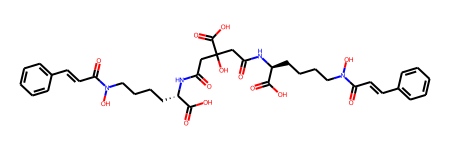

In [30]:
mols[indexer_original_mols.index('SF_0189')]

In [34]:
rxn = REACTIONS['olefin']
rtnts = (mols[indexer_original_mols.index('SF_0189')], )
products = rxn.RunReactants(rtnts)
products

((<rdkit.Chem.rdchem.Mol at 0x7f5da5583870>,
  <rdkit.Chem.rdchem.Mol at 0x7f5da5583f30>),
 (<rdkit.Chem.rdchem.Mol at 0x7f5da5583a50>,
  <rdkit.Chem.rdchem.Mol at 0x7f5da55839f0>),
 (<rdkit.Chem.rdchem.Mol at 0x7f5da55831b0>,
  <rdkit.Chem.rdchem.Mol at 0x7f5da55832d0>),
 (<rdkit.Chem.rdchem.Mol at 0x7f5da5583210>,
  <rdkit.Chem.rdchem.Mol at 0x7f5da55834b0>))

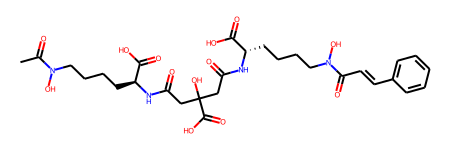

In [56]:
products[3][1]

In [23]:
fragmentator.plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

In [22]:
fragmentator_old.plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

# 2. Run the process with all the compounds

## 2.1. Create graphs

#### <span style="color:red">BEWARE</span>: Aprox time to execute with 1853 molecules: 15-20 mins

#### <span style="color:red">BEWARE</span>: Aprox time to execute with 4034 molecules: 60 mins aprox

In [ ]:
# Run the process without MD, for unknown compounds
result_graphs, UCL, unknown_occurrences = geass.create_graphs_without_MD(mols, indexer_original_mols, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, UCL, old_version=True)

In [19]:
result_graphs, disassembled_ids, analytics_result = geass.create_graphs(mols, indexer_original_mols, PBU, BUL, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames)

PROGRESS: [4034/4034]
Elapsed: 3580.301s


In [25]:
result_graphs, disassembled_ids, analytics_result = geass.create_graphs([mols[indexer_original_mols.index('SF_0406')]], indexer_original_mols, PBU, BUL, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames)

PROGRESS: [1/1]
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
No boundary bonds
Error
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Elapsed: 0.701s


In [32]:
result_graphs_old, disassembled_ids_old, analytics_result_old = geass.create_graphs(mols, indexer_original_mols, PBU, BUL, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, old_version=True)

PROGRESS: [4034/4034]


Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Elapsed: 2874.04s


In [60]:
result_graphs_peptides_old, disassembled_ids_peptides_old, analytics_result_peptides_old = geass.create_graphs(peptide_mols, peptide_names, PBU, BUL, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, old_version=True)

PROGRESS: [4465/4465]
Elapsed: 256.026s


In [101]:
result_graphs_old

{'BS_0002': <geass.Geass at 0x7f30afbd7650>,
 'BS_0003': <geass.Geass at 0x7f30a2b3b8d0>,
 'BS_0004': <geass.Geass at 0x7f30a51e8150>,
 'BS_0008': <geass.Geass at 0x7f308f604990>,
 'BS_0031': <geass.Geass at 0x7f30461b3590>,
 'BS_0032': <geass.Geass at 0x7f308f42ce90>,
 'BS_0036': <geass.Geass at 0x7f304b55ed10>,
 'BS_0039': <geass.Geass at 0x7f304c1b3790>,
 'BS_0040': <geass.Geass at 0x7f309de85110>,
 'BS_0041': <geass.Geass at 0x7f30418d0b90>,
 'BS_0049': <geass.Geass at 0x7f309b1b30d0>,
 'BS_0054': <geass.Geass at 0x7f309e54b610>,
 'BS_0056': <geass.Geass at 0x7f303ced3410>,
 'BS_0059': <geass.Geass at 0x7f304cb732d0>,
 'BS_0061': <geass.Geass at 0x7f30496e4550>,
 'BS_0062': <geass.Geass at 0x7f30983947d0>,
 'BS_0066': <geass.Geass at 0x7f3052792bd0>,
 'BS_0067': <geass.Geass at 0x7f30515ed110>,
 'BS_0069': <geass.Geass at 0x7f3057953c50>,
 'BS_0070': <geass.Geass at 0x7f30407ad3d0>,
 'BS_0071': <geass.Geass at 0x7f3098ba2290>,
 'BS_0072': <geass.Geass at 0x7f308c2bd8d0>,
 'BS_0075'

In [98]:
geass_graphs = {k: v.graph for k, v in result_graphs_old.items()}
print('Starting pickling')
with open('result_graphs_Jan24.pkl', 'wb') as f:
    pickle.dump(geass_graphs, f)

Starting pickling


In [90]:
df_mcs = pd.read_csv('For MCS file 1.csv')

In [93]:
number_of_clusters = df_mcs['__ccCluster'].unique()
number_of_clusters

array([   1,    2,    3, ..., 1518, 1519, 1520])

In [95]:
df_mcs.loc[df_mcs['__ccCluster'] == number_of_clusters[0]]

,shared name,BGC,__ccCluster,SMILES_manual,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,5
0,LTS0271673,NaN,1,C1=C(C=C2C(=C1O)C(=O)C(=C(O2)C3=CC(=C(C=C3O)O)...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0
1,LTS0269273,NaN,1,CC1=C(C2=C(C=C1O)OC(=CC2=O)C3=CC(=C(C=C3)O)O)O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0
2,LTS0268543,NaN,1,C1=CC=C(C=C1)C2=CC(=O)C3=C(C=CC=C3O2)O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0
3,LTS0260159,NaN,1,C1=CC(=CC=C1C2=CC(=O)C3=C(O2)C=C(C=C3)O)O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0
4,LTS0259993,NaN,1,COC1=CC(=C2C(=C1)OC(=CC2=O)C3=CC(=C(C=C3)O)O)O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,SF_0563,NaN,1,C1=CC(=CC=C1C2=CC(=O)C3=C(C=C(C=C3O2)O)O)O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,280.0
64,SF_0562,NaN,1,C1=CC=C(C=C1)C2=CC(=O)C3=C(C=C(C=C3O2)O)O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,281.0
65,SF_0558,NaN,1,C1=C(C=C(C(=C1O)O)O)C2=C(C(=O)C3=C(C=C(C=C3O2)...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,282.0
66,SF_0557,NaN,1,C1=CC(=C(C=C1C2=CC(=O)C3=C(C=C(C=C3O2)O)O)O)O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,283.0


In [96]:
ISMAGS_obj = nx.algorithms.isomorphism.ISMAGS(result_graphs_old['SF_0563'].graph, result_graphs_old['SF_0562'].graph)

AttributeError: module 'networkx.algorithms.isomorphism' has no attribute 'ISMAGS'

In [ ]:
for shared_name_1, graph_1 in result_graphs_old.items():
    for shared_name_2, graph_2 in result_graphs_old.items():
        if(shared_name_1 != shared_name_2):
            ISMAGS_obj = nx.algorithms.isomorphism.ISMAGS(graph_1, graph_2)


In [14]:
analytics_result_old

{'Fragmented All NP': [],
 'Fragmented not NP OK': ['BS_0002'],
 'Fragmented not NP ERROR': [],
 'Not fragmented All NP': [],
 'Not fragmented not NP OK': [],
 'Not fragmented not NP ERROR': []}

#### <span style="color:red">BEWARE</span>: Aprox time to execute with 4034 molecules: 90 mins aprox

In [28]:
result_graphs_lipids, disassembled_ids_lipids, analytics_result_lipids = geass.create_graphs(mols, indexer_original_mols, PBU, BUL, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames_lipids)

PROGRESS: [4034/4034]
Elapsed: 5499.719s


In [33]:
result_graphs_old_lipids, disassembled_ids_old_lipids, analytics_result_old_lipids = geass.create_graphs(mols, indexer_original_mols, PBU, BUL, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames_lipids, old_version=True)

PROGRESS: [4034/4034]
Elapsed: 4405.93s


In [ ]:
# result_graphs, disassembled_ids, analytics_result = geass.create_graphs(mols, indexer_original_mols, PBU, BUL, BROKEN_BONDS_LIPIDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames)

In [144]:
lipid_mols

{'10930192': <rdkit.Chem.rdchem.Mol at 0x7f30130aa770>,
 '42607281': <rdkit.Chem.rdchem.Mol at 0x7f300de56cb0>,
 '42607282': <rdkit.Chem.rdchem.Mol at 0x7f300de561f0>,
 '5470079': <rdkit.Chem.rdchem.Mol at 0x7f30afa76570>,
 '42607283': <rdkit.Chem.rdchem.Mol at 0x7f300de633f0>,
 '42607284': <rdkit.Chem.rdchem.Mol at 0x7f300d64d570>,
 '142752': <rdkit.Chem.rdchem.Mol at 0x7f300d64d2b0>,
 '23724633': <rdkit.Chem.rdchem.Mol at 0x7f300d64d230>,
 '895': <rdkit.Chem.rdchem.Mol at 0x7f300d64d1f0>,
 '5712057': <rdkit.Chem.rdchem.Mol at 0x7f300d64d630>,
 '52921723': <rdkit.Chem.rdchem.Mol at 0x7f300d64de70>,
 '42607315': <rdkit.Chem.rdchem.Mol at 0x7f300d64dcb0>,
 '56935790': <rdkit.Chem.rdchem.Mol at 0x7f300d64ddb0>,
 '56935791': <rdkit.Chem.rdchem.Mol at 0x7f300d64dcf0>,
 '56935792': <rdkit.Chem.rdchem.Mol at 0x7f300d64d730>,
 '56935793': <rdkit.Chem.rdchem.Mol at 0x7f300d64daf0>,
 '56935794': <rdkit.Chem.rdchem.Mol at 0x7f300d64d530>,
 '56935795': <rdkit.Chem.rdchem.Mol at 0x7f300d64deb0>,
 

In [148]:
lipid_geass_result = {}
for mol_index, (mol_id, current_mol) in enumerate(lipid_mols.items()):
    clear_output()
    print(f'PROGRESS: [{mol_index+1}/{len(lipid_mols)}]')
    # Initialize Geass
    fragmentator = geass.Geass(current_mol, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, verbose=0)

    # Get bonds to break
    fragmentator.get_bonds_to_break()
    
    # Create graph
    fragmentator.create_fragmentation_graph_old()
    
    lipid_geass_result[mol_id] = fragmentator

PROGRESS: [47362/47362]
No breakable bonds were found. Impossible to create the fragmentation graph.


In [149]:
lipid_geass_result

{'10930192': <geass.Geass at 0x7f300c754a50>,
 '42607281': <geass.Geass at 0x7f30395c9650>,
 '42607282': <geass.Geass at 0x7f303a3125d0>,
 '5470079': <geass.Geass at 0x7f300e344210>,
 '42607283': <geass.Geass at 0x7f300e634a50>,
 '42607284': <geass.Geass at 0x7f30322662d0>,
 '142752': <geass.Geass at 0x7f300d1447d0>,
 '23724633': <geass.Geass at 0x7f3031da1490>,
 '895': <geass.Geass at 0x7f300e5c5150>,
 '5712057': <geass.Geass at 0x7f300e96f0d0>,
 '52921723': <geass.Geass at 0x7f300df69b90>,
 '42607315': <geass.Geass at 0x7f3039814b90>,
 '56935790': <geass.Geass at 0x7f300d05f4d0>,
 '56935791': <geass.Geass at 0x7f300e02f5d0>,
 '56935792': <geass.Geass at 0x7f300d05fe10>,
 '56935793': <geass.Geass at 0x7f300e2e0dd0>,
 '56935794': <geass.Geass at 0x7f300d05fb90>,
 '56935795': <geass.Geass at 0x7f300e612c90>,
 '56935796': <geass.Geass at 0x7f300d05f510>,
 '56935797': <geass.Geass at 0x7f300c7546d0>,
 '56935798': <geass.Geass at 0x7f300e5630d0>,
 '56935799': <geass.Geass at 0x7f3013b88210

In [151]:
lipid_geass_result['5312648'].plot_graph()

CytoscapeWidget(cytoscape_layout={'name': 'circle', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style…

### 2.1.1. Optional: Store analytics

In [34]:
csv_string = 'ID_UNIQUE,"Compounds ids"\n'
for k, v in disassembled_ids_old.items():
    csv_string += k + ',"' + str(v) + '"\n'
with open('dissasembled_v1_Jan24.csv', 'w') as csv_file:
    csv_file.write(csv_string)

In [35]:
csv_string = 'ID_UNIQUE,"Compounds ids"\n'
for k, v in disassembled_ids_old_lipids.items():
    csv_string += k + ',"' + str(v) + '"\n'
with open('dissasembled_lipids_v1_Jan24.csv', 'w') as csv_file:
    csv_file.write(csv_string)

In [61]:
csv_string = 'ID_UNIQUE,"Compounds ids"\n'
for k, v in disassembled_ids_peptides_old.items():
    csv_string += k + ',"' + str(v) + '"\n'
with open('dissasembled_peptides_v1_Jan24.csv', 'w') as csv_file:
    csv_file.write(csv_string)

In [63]:
analytics_df = pd.DataFrame()
analytics_df['Fragmented All NP'] = analytics_result_old['Fragmented All NP']
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Fragmented not NP OK': analytics_result_old['Fragmented not NP OK']})], axis=1)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Fragmented not NP ERROR': analytics_result_old['Fragmented not NP ERROR']})], axis=1)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented All NP': analytics_result_old['Not fragmented All NP']})], axis=1)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented not NP OK': analytics_result_old['Not fragmented not NP OK']})], axis=1)
analytics_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented not NP ERROR': analytics_result_old['Not fragmented not NP ERROR']})], axis=1)

In [37]:
analytics_lipids_df = pd.DataFrame()
analytics_lipids_df['Fragmented All NP'] = analytics_result_old_lipids['Fragmented All NP']
analytics_lipids_df = pd.concat([analytics_lipids_df, pd.DataFrame({'Fragmented not NP OK': analytics_result_old_lipids['Fragmented not NP OK']})], axis=1)
analytics_lipids_df = pd.concat([analytics_lipids_df, pd.DataFrame({'Fragmented not NP ERROR': analytics_result_old_lipids['Fragmented not NP ERROR']})], axis=1)
analytics_lipids_df = pd.concat([analytics_lipids_df, pd.DataFrame({'Not fragmented All NP': analytics_result_old_lipids['Not fragmented All NP']})], axis=1)
analytics_lipids_df = pd.concat([analytics_lipids_df, pd.DataFrame({'Not fragmented not NP OK': analytics_result_old_lipids['Not fragmented not NP OK']})], axis=1)
analytics_lipids_df = pd.concat([analytics_lipids_df, pd.DataFrame({'Not fragmented not NP ERROR': analytics_result_old_lipids['Not fragmented not NP ERROR']})], axis=1)

In [64]:
analytics_peptides_df = pd.DataFrame()
analytics_peptides_df['Fragmented All NP'] = analytics_result_peptides_old['Fragmented All NP']
analytics_peptides_df = pd.concat([analytics_df, pd.DataFrame({'Fragmented not NP OK': analytics_result_peptides_old['Fragmented not NP OK']})], axis=1)
analytics_peptides_df = pd.concat([analytics_df, pd.DataFrame({'Fragmented not NP ERROR': analytics_result_peptides_old['Fragmented not NP ERROR']})], axis=1)
analytics_peptides_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented All NP': analytics_result_peptides_old['Not fragmented All NP']})], axis=1)
analytics_peptides_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented not NP OK': analytics_result_peptides_old['Not fragmented not NP OK']})], axis=1)
analytics_peptides_df = pd.concat([analytics_df, pd.DataFrame({'Not fragmented not NP ERROR': analytics_result_peptides_old['Not fragmented not NP ERROR']})], axis=1)

In [38]:
analytics_df.to_csv("geass_and_MD_analytics_v1_Jan24.csv", index=False)

In [39]:
analytics_lipids_df.to_csv("geass_and_MD_analytics_lipids_v1_Jan24.csv", index=False)

In [65]:
analytics_peptides_df.to_csv("geass_and_MD_analytics_peptides_v1_Jan24.csv", index=False)

## 2.2. Create compound edges collection for similarity calculation

In [69]:
compound_edges = geass.create_compound_edges(result_graphs_old)
compound_edges_all = compound_edges.copy()

In [41]:
compound_edges_lipids = geass.create_compound_edges(result_graphs_old_lipids)

In [66]:
compound_edges_peptides = geass.create_compound_edges(result_graphs_peptides_old)

In [134]:
result_graphs_old_lipids['BS_0049'].graph.nodes(data=True)[1]

{'SMILES': '[H]O[C@@H]1O[C@H](C)C[CH][C@H]1O',
 'img': 'data:image/svg+xml;charset=utf-8,%3C%3Fxml%20version%3D%271.0%27%20encoding%3D%27iso-8859-1%27%3F%3E%0A%3Csvg%20version%3D%271.1%27%20baseProfile%3D%27full%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3D%27http%3A%2F%2Fwww.w3.org%2F2000%2Fsvg%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Ardkit%3D%27http%3A%2F%2Fwww.rdkit.org%2Fxml%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xmlns%3Axlink%3D%27http%3A%2F%2Fwww.w3.org%2F1999%2Fxlink%27%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20xml%3Aspace%3D%27preserve%27%0Awidth%3D%27350px%27%20height%3D%27300px%27%20viewBox%3D%270%200%20350%20300%27%3E%0A%3C%21--%20END%20OF%20HEADER%20--%3E%0A%3Crect%20style%3D%27opacity%3A1.0%3Bfill%3A%23FFFFFF%3Bstroke%3Anone%27%20width%3D%27350.0%27%20height%3D%27300.0%27%20x%3D%270.0%27%20y%3D%270.0%27%3E%20%3C%2Frect%3E%0A%3Cpath%20class%3D%27bond-0%20atom-1%20atom-0%27%20d%3D%2

In [136]:
result_graphs_old_lipids['BS_0049'].graph.edges(data=True)

EdgeDataView([(0, 1, {'reaction': 'etherR'}), (1, 2, {'reaction': 'aminesR'}), (2, 3, {'reaction': 'aminesR'}), (2, 4, {'reaction': 'aminesR'})])

In [111]:
compound_edges_peptides

{'Pep1': (('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR')),
 'pep2': (('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00047', 'amideR')),
 'Pep3': (('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00062', 'amideR'),
  ('C00062', 'C00062', 'amideR'),
  ('C00062', 'C00062', 'amideR'),
  ('C00062', 'C00062', 'amideR')),
 'Pep4': (('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00047', 'amideR')),
 'Pep5': (('C00073', 'C00041', 'amideR'),
  ('C00073', 'C00065', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00041', 'C00041', 'amideR'),
  ('C00065', 'C00064', 'amideR'),
  ('C00064', 'C00183', 'amideR'),
  ('

In [73]:
compound_edges_all = dict(compound_edges_all, **compound_edges_peptides)

In [80]:
# Create csv with all edges (nodes and reation type)
edge_csv_string = 'ID,n1,n2,ReactionType'
for id, edges in compound_edges_all.items():
    for edge in edges:
        edge_csv_string = '\n'.join([edge_csv_string, f'{id},{",".join(edge)}'])

In [186]:
# Create csv with all edges (nodes and reation type)
edge_csv_string = 'ID,n1,n2,ReactionType'
for id, edges in compound_edges.items():
    for edge in edges:
        edge_csv_string = '\n'.join([edge_csv_string, f'{id},{",".join(edge)}'])

In [82]:
# Create csv with all edges (nodes and reation type)
edge_csv_string_aux = 'ID,n1,n2,ReactionType\n'
for id, edges in compound_edges_all.items():
    for edge in edges:
        edge_csv_string_aux = f'{edge_csv_string_aux}{id},{",".join(edge)}\n'

In [122]:
edge_lipids_csv_string = 'ID,n1,n2,ReactionType'
for id, edges in compound_edges_lipids.items():
    for edge in edges:
        edge_lipids_csv_string = '\n'.join([edge_lipids_csv_string, f'{id},{",".join(edge)}'])

In [187]:
with open('SECRETed_edges.csv', 'w') as csv_file:
    csv_file.write(edge_csv_string)

In [81]:
with open('SECRETed+peptides_edges.csv', 'w') as csv_file:
    csv_file.write(edge_csv_string)

In [123]:
with open('SECRETed_lipids_edges.csv', 'w') as csv_file:
    csv_file.write(edge_lipids_csv_string)

## 2.3. Create similarity matrix

In [42]:
similarity_df = geass.create_similarity_matrix(compound_edges)

Elapsed: 442.836s


In [43]:
similarity_lipids_df = geass.create_similarity_matrix(compound_edges_lipids)

Elapsed: 429.372s


In [86]:
similarity_peptides_df = geass.create_similarity_matrix(compound_edges_peptides)

Elapsed: 669.153s


In [85]:
similarity_all_df = geass.create_similarity_matrix(compound_edges_all)

Elapsed: 2212.427s


### 2.3.1. Optional: Store similarity matrix

In [110]:
similarity_df.shape

(4034, 4034)

In [44]:
similarity_df.to_csv('similarity_matrix_v1_Jan24.csv')

In [45]:
similarity_lipids_df.to_csv('similarity_matrix_lipids_v1_Jan24.csv')

In [87]:
similarity_peptides_df.to_csv('similarity_matrix_peptides_v1_Jan24.csv')

In [88]:
similarity_all_df.to_csv('similarity_matrix_SECRETed+peptides_v1_Jan24.csv')

# 3. Same process but with MIBiG

## 3.1. Loading required molecules

In [11]:
# sdf_filename = 'data/MIBIG-3.1-mergedComps.sdf'
sdf_filename = 'unified-MIBIG 5.sdf'
df_mibig = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule', strictParsing=True)
# Molecules
mibig_mols = list(df_mibig['Molecule'])
# Indexes
mibig_indexes = list(df_mibig['ID'])

RDKit WARNING: [12:47:39] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [12:47:39] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [12:47:39] WARNING: not removing hydrogen atom without neighbors
RDKit WARNING: [12:47:39] WARNING: not removing hydrogen atom without neighbors
[12:47:39] WARNING: not removing hydrogen atom without neighbors
[12:47:39] WARNING: not removing hydrogen atom without neighbors
[12:47:39] WARNING: not removing hydrogen atom without neighbors
[12:47:39] WARNING: not removing hydrogen atom without neighbors


## 3.2. Run Geass + MD

In [12]:
# Run the process without MD, for unknown compounds
result_mibig_graphs, UCL, unknown_mibig_occurrences = geass.create_graphs_without_MD(mibig_mols, mibig_indexes, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, UCL, old_version=True)

PROGRESS: [2318/2318]
Elapsed: 579.183s


In [16]:
# Update the UCL pickle
with open('data/UCL.pkl', 'wb') as f:
    pickle.dump(UCL, f)

In [20]:
# Save UCL occurrences
with open('UCL_occurrences_MIBiG.csv', 'w') as csv_file:  
    writer = csv.writer(csv_file)
    writer.writerow(["ID", "Matches", "Count", "SMILES"])
    for key, value in unknown_mibig_occurrences.items():
       writer.writerow([key, value, len(value), Chem.MolToSmiles(UCL[key])])

#### <span style="color:red">BEWARE</span>: Aprox time to execute with MIBiG molecules: 25 mins

In [19]:
# result_mibig_graphs, disassembled_mibig_ids, analytics_result_mibig = geass.create_graphs(mibig_mols, mibig_indexes, PBU, BUL, BROKEN_BONDS, REACTANTS, FILLING_ATOMS, BULnames)
result_mibig_graphs, disassembled_mibig_ids, analytics_result_mibig = geass.create_graphs(mibig_mols, mibig_indexes, PBU, BUL, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, old_version=True)

PROGRESS: [2318/2318]
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Our lib correctly loaded! Of size: 16652


RDKit WARNING: [12:08:31] WARNING: Omitted undefined stereo
ereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefined stereo
[12:08:31] WARNING: Omitted undefin

Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 3
Finished.
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Our lib correctly loaded! Of size: 16652
Our PBU correctly loaded! Of size: 5006
Len seed_list before optimising: 1
Finished.
Elapsed: 1584.07s


In [20]:
csv_string = 'ID_UNIQUE,"Compounds ids"\n'
for k, v in disassembled_mibig_ids.items():
    csv_string += k + ',"' + str(v) + '"\n'
with open('dissasembled_mibig_v1_Jan24.csv', 'w') as csv_file:
    csv_file.write(csv_string)

In [21]:
analytics_mibig_df = pd.DataFrame()
analytics_mibig_df['Fragmented All NP'] = analytics_result_mibig['Fragmented All NP']
analytics_mibig_df = pd.concat([analytics_mibig_df, pd.DataFrame({'Fragmented not NP OK': analytics_result_mibig['Fragmented not NP OK']})], axis=1)
analytics_mibig_df = pd.concat([analytics_mibig_df, pd.DataFrame({'Fragmented not NP ERROR': analytics_result_mibig['Fragmented not NP ERROR']})], axis=1)
analytics_mibig_df = pd.concat([analytics_mibig_df, pd.DataFrame({'Not fragmented All NP': analytics_result_mibig['Not fragmented All NP']})], axis=1)
analytics_mibig_df = pd.concat([analytics_mibig_df, pd.DataFrame({'Not fragmented not NP OK': analytics_result_mibig['Not fragmented not NP OK']})], axis=1)
analytics_mibig_df = pd.concat([analytics_mibig_df, pd.DataFrame({'Not fragmented not NP ERROR': analytics_result_mibig['Not fragmented not NP ERROR']})], axis=1)

In [22]:
analytics_mibig_df.to_csv("geass_and_MD_analytics_mibig_v1_Jan24.csv", index=False)

## 3.3. Create compound edges collection

In [23]:
compound_edges_mibig = geass.create_compound_edges(result_mibig_graphs)

In [24]:
# Create csv with all edges (nodes and reation type)
edge_csv_string_mibig = 'ID,n1,n2,ReactionType'
for id, edges in compound_edges_mibig.items():
    for edge in edges:
        edge_csv_string_mibig = '\n'.join([edge_csv_string_mibig, f'"{id}",{",".join(edge)}'])

In [25]:
with open('MIBiG_edges.csv', 'w') as csv_file:
    csv_file.write(edge_csv_string_mibig)

### 3.3.1. Combine SECRETed compound edges with MIBiG compound edges

In [200]:
compound_edges_all = compound_edges.copy()
compound_edges_all.update(compound_edges_mibig)

## 3.4. Get similarity matrix

In [120]:
similarity_df_mibig = geass.create_similarity_matrix(compound_edges_mibig)

Elapsed: 166.606s


In [205]:
similarity_df_all = geass.create_similarity_matrix(compound_edges_all)

Elapsed: 241.475s


### 3.4.1. Optional: store similarity matrix

In [121]:
similarity_df_mibig.to_csv('similarity_matrix_mibig_v1_Jan24.csv')

In [207]:
# similarity_df_all.to_csv('similarity_matrix_mibig.csv')

## PREPARATION FOR REVERSE REACTIONS

In [188]:
df_edges = pd.read_csv('SECRETed_edges.csv')
df_edges

,ID,n1,n2,ReactionType
0,BS_0002,C06423+C01438+C00001,C00183,amideR
1,BS_0002,C06423+C01438+C00001,C06423,unknown
2,BS_0002,C06423+C01438+C00001,C01438,unknown
3,BS_0002,C06423+C01438+C00001,C00001,unknown
4,BS_0002,C00183,C03283,amideR
...,...,...,...,...
32262,LTS0275969,C21390+C01438,C21390,unknown
32263,LTS0275969,C21390+C01438,C01438,unknown
32264,LTS0276508,C01530+C00001,C00031,etherR
32265,LTS0276508,C01530+C00001,C01530,unknown


In [161]:
with open('kegg_lipids.json', 'r') as json_file:
    kegg_lipids = json.load(json_file)

In [183]:
kegg_lipid_ids = list(kegg_lipids.keys())

In [199]:
reaction_with_molecules = {}

In [197]:
Counter(['a', 'b', 'a', 'c', 'a', 'b']).values()

dict_values([3, 2, 1])

In [210]:
pd.isna(df_edges.loc[df_edges['ID'] == 'BS_0039']['n1'][67])

True

In [211]:
all_ids = df_edges['ID'].unique()
all_kegg_ids = list(kegg_lipids.keys())
# Iterate through the SECRETed mol ids
for id in all_ids:
    reaction_occurrences = []
    # Get all the rows of the dataframe of current mol
    mol_rows = df_edges.loc[df_edges['ID'] == id]
    for idx in mol_rows.index:
        # Check if the current row has any lipids and if so, save the reaction type in the auxiliary reaction list
        if mol_rows['ReactionType'][idx] != 'unknown' and any(not pd.isna(mol_rows['n1'][idx]) and k_id in mol_rows['n1'][idx] or not pd.isna(mol_rows['n2'][idx]) and k_id in mol_rows['n2'][idx] for k_id in all_kegg_ids):
            reaction_occurrences.append(mol_rows['ReactionType'][idx])
    # Count each reaction occurrence
    reaction_counter = Counter(reaction_occurrences)
    # Only select the reactions that have 1 or 2 occurrences
    reactions_to_add = [r for r, count in reaction_counter.items() if count < 3]
    # Add the mol to the result reaction dict
    for r in reactions_to_add:
        if r not in reaction_with_molecules:
            reaction_with_molecules[r] = []
        reaction_with_molecules[r].append(id)

In [221]:
# Dataframe result
df_edges_with_lipids_reactions = pd.DataFrame()
for id in kegg_lipids.keys():
    matching_rows = df_edges.loc[df_edges['n1'].str.contains(id) | df_edges['n2'].str.contains(id)]
    if not matching_rows.empty:
        matching_rows['LipidID'] = id
        df_edges_with_lipids_reactions = df_edges_with_lipids_reactions.append(matching_rows)
        # for idx in matching_rows.index:
        #     if matching_rows['ReactionType'][idx] not in reaction_with_molecules:
        #         reaction_with_molecules[matching_rows['ReactionType'][idx]] = []
        #     reaction_with_molecules[matching_rows['ReactionType'][idx]].append(matching_rows['ID'][idx])

/home/ubuntu/anaconda3/envs/map4_test2/lib/python3.7/site-packages/ipykernel_launcher.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


In [222]:
df_edges_with_lipids_reactions

,ID,n1,n2,ReactionType,LipidID
286,BS_0082,C00073,C00058,amideR,C00058
366,BS_0084,C00073,C00058,amideR,C00058
396,BS_0086,C00073,C00058,amideR,C00058
760,BS_0141,C00033,C20809+C00058+C00001,olefin,C00058
761,BS_0141,C20809+C00058+C00001,C20809,unknown,C00058
...,...,...,...,...,...
29352,LTS0223488,C10809+C00001,C00132,etherR,C10809
29353,LTS0223488,C10809+C00001,C10809,unknown,C10809
29354,LTS0223488,C10809+C00001,C00001,unknown,C10809
30566,LTS0245341,C10809+C01438,C10809,unknown,C10809


In [223]:
df_edges_with_lipids_reactions.to_csv("edges_with_lipids_reactions.csv")

In [479]:
with open('reaction_with_molecules.json', 'w') as json_file:
    json.dump(reaction_with_molecules, json_file)

In [213]:
reaction_with_molecules

{'amideR': ['BS_0002',
  'BS_0003',
  'BS_0004',
  'BS_0002',
  'BS_0003',
  'BS_0004',
  'BS_0002',
  'BS_0003',
  'BS_0004',
  'BS_0066',
  'BS_0069',
  'BS_0070',
  'BS_0075',
  'BS_0076',
  'BS_0078',
  'BS_0080',
  'BS_0082',
  'BS_0084',
  'BS_0086',
  'BS_0087',
  'BS_0088',
  'BS_0089',
  'BS_0090',
  'BS_0091',
  'BS_0092',
  'BS_0104',
  'BS_0108',
  'BS_0109',
  'BS_0112',
  'BS_0130',
  'BS_0140',
  'BS_0141',
  'BS_0161',
  'BS_0162',
  'BS_0163',
  'BS_0164',
  'BS_0165',
  'BS_0168',
  'BS_0179',
  'BS_0180',
  'BS_0195',
  'BS_0196',
  'BS_0202',
  'BS_0203',
  'BS_0204',
  'BS_0205',
  'BS_0206',
  'BS_0208',
  'BS_0214',
  'BS_0220',
  'BS_0221',
  'BS_0222',
  'BS_0225',
  'BS_0235',
  'BS_0241',
  'BS_0247',
  'BS_0248',
  'BS_0249',
  'BS_0255',
  'BS_0260',
  'BS_0261',
  'BS_0264',
  'BS_0269',
  'BS_0271',
  'BS_0275',
  'BS_0276',
  'BS_0284',
  'BS_0288',
  'BS_0289',
  'BS_0292',
  'BS_0295',
  'BS_0299',
  'BS_0300',
  'BS_0305',
  'BS_0306',
  'BS_0309',
  

In [192]:
reaction_with_molecules.keys()

dict_keys(['amideR', 'olefin', 'unknown', 'etherR', 'cyclicAmines', 'arCarCR', 'aminesR', 'ureaR', 'laNalC', 'arNalC'])

In [224]:
{k: len(v) for k, v in reaction_with_molecules.items()}

{'amideR': 872,
 'etherR': 1184,
 'olefin': 705,
 'cyclicAmines': 62,
 'arCarCR': 33,
 'laNalC': 20,
 'aminesR': 88,
 'ureaR': 10,
 'arNalC': 4}

In [298]:
reaction_with_molecules['etherR'][225:251]

['BS_1141',
 'BS_1142',
 'BS_1143',
 'BS_1144',
 'BS_1145',
 'BS_1147',
 'BS_1173',
 'BS_1175',
 'BS_1178',
 'BS_1181',
 'BS_1183',
 'BS_1184',
 'BS_1185',
 'BS_1186',
 'BS_1187',
 'BS_1190',
 'BS_1191',
 'BS_1192',
 'BS_1193',
 'BS_1194',
 'BS_1201',
 'BS_1203',
 'BS_1204',
 'BS_1205',
 'BS_1206',
 'BS_1207']

## Test with etherR

Currently tested:

- &#9745; BS_0069
- &#9746; BS_0075 (not creating 2 fragments)
- ? BS_0145 (multiple choices)
- ? BS_0146 (multiple choices)
- &#9745; BS_0148
- ? BS_0203 (not sure if result is a valid lipid)
- ? BS_0290 (LOTS of results)
- ? BS_0351 (not sure if result is a lipid)
- ? BS_1187 (many results and not sure if result is a lipid)
- &#9745; BS_1207 (BUT 2 results and the 2nd may be the best)

In [383]:
fragmentator = geass.Geass(mols[indexer_original_mols.index('BS_0069')], BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, verbose=0) # Default Geass

In [334]:
fragmentator.get_bonds_to_break()

In [335]:
fragmentator.breakable_mol_bonds

{7: 'etherR', 12: 'etherR'}

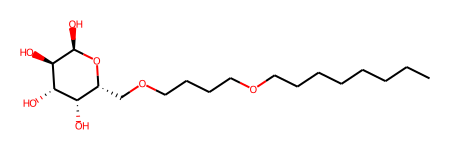

In [415]:
mol_to_fragment = mols[indexer_original_mols.index('BS_1207')]
mol_to_fragment

In [416]:
rxn = REACTIONS['etherR']
rtnts = (mol_to_fragment, )
products = rxn.RunReactants(rtnts)
products

((<rdkit.Chem.rdchem.Mol at 0x7f2feda056f0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fedd9ccf0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2feda4cb10>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2feda4c390>,))

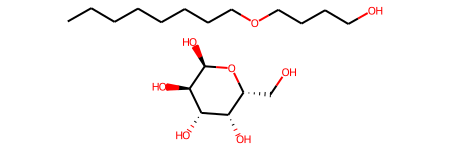

In [419]:
products[2][0]

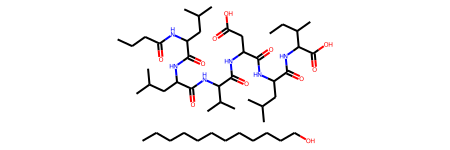

In [414]:
fragmented1 = products[0][0]
fragmented1

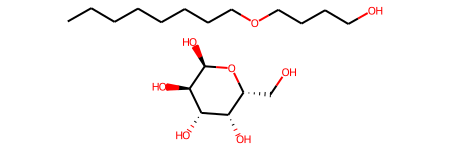

In [420]:
fragmented2 = products[2][0]
fragmented2

In [422]:
smiles_aux = geass.to_smiles((fragmented1,))
tpl_prod = geass.from_smiles(smiles_aux)
frags1 = Chem.GetMolFrags(tpl_prod[0], asMols=True)
smiles_aux = geass.to_smiles((fragmented2,))
tpl_prod = geass.from_smiles(smiles_aux)
frags2 = Chem.GetMolFrags(tpl_prod[0], asMols=True)

In [427]:
geass.to_smiles((fragmented1,))

('CCCC(=O)NC(CC(C)C)C(=O)NC(CC(C)C)C(=O)NC(C(=O)NC(CC(=O)O)C(=O)NC(CC(C)C)C(=O)NC(C(=O)O)C(C)CC)C(C)C.CCCCCCCCCCCCO',)

In [428]:
geass.to_smiles((fragmented2,))

('CCCCCCCCOCCCCO.OC[C@H]1O[C@H](O)[C@H](O)[C@@H](O)[C@H]1O',)

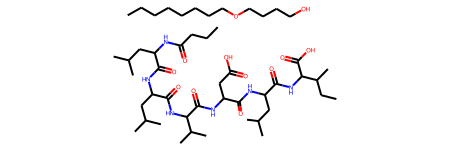

In [488]:
fragmented3 = geass.from_smiles(('CCCC(=O)NC(CC(C)C)C(=O)NC(CC(C)C)C(=O)NC(C(=O)NC(CC(=O)O)C(=O)NC(CC(C)C)C(=O)NC(C(=O)O)C(C)CC)C(C)C.CCCCCCCCOCCCCO',))
fragmented3[0]

In [426]:
frags1

(<rdkit.Chem.rdchem.Mol at 0x7f2fed9f7cf0>,
 <rdkit.Chem.rdchem.Mol at 0x7f2fed9f7810>)

In [360]:
reverseEtherRSMARTS = "([#6:1][O].[O][#6:2])>>[#6:1]-[O;+0;!r6;!r5]-[#6:2]"
rxn = Chem.rdChemReactions.ReactionFromSmarts(reverseEtherRSMARTS)
rxn.GetNumProductTemplates()

1

In [489]:
# Trying reverse RunReactants
reverseEtherRSMARTS = "([#6:1][O].[O][#6:2])>>[#6:1]-[O;+0;!r6;!r5]-[#6:2]"
rxn = Chem.rdChemReactions.ReactionFromSmarts(reverseEtherRSMARTS)
reverse_rtnts = (fragmented3[0],)
reverse_products = rxn.RunReactants(reverse_rtnts)
reverse_products

((<rdkit.Chem.rdchem.Mol at 0x7f2fed9fba50>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252810>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee2528d0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee2527b0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252870>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee2529f0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252a50>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252990>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252ab0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252b10>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252b70>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252bd0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252c30>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252c90>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252cf0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252d50>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252db0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee252e10>,))

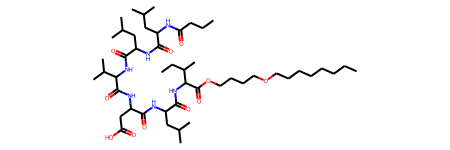

In [499]:
reverse_products[7][0]

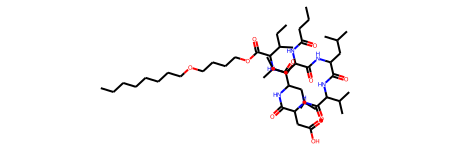

In [491]:
smiles_aux = geass.to_smiles((reverse_products[7][0],))
tpl_prod = geass.from_smiles(smiles_aux)
tpl_prod[0]


In [494]:
rxn = REACTIONS['etherR']
rtnts = tpl_prod
products = rxn.RunReactants(rtnts)
products

((<rdkit.Chem.rdchem.Mol at 0x7f2fee145d50>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee145cf0>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee145e10>,),
 (<rdkit.Chem.rdchem.Mol at 0x7f2fee145e70>,))

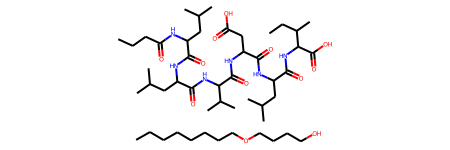

In [502]:
products[2][0]

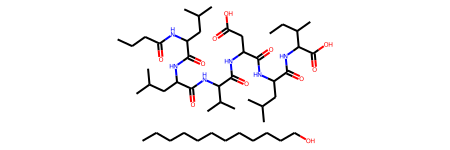

In [472]:
fragmented1

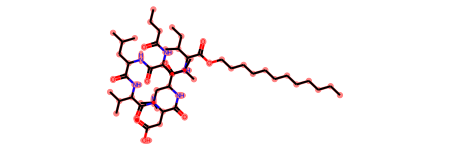

In [411]:
mol_to_fragment = mols[indexer_original_mols.index('BS_0069')]
mol_to_fragment

In [503]:
len(fragmented3[0].GetSubstructMatch(products[2][0], )) == fragmented3[0].GetNumAtoms()

True

In [496]:
len(mol_to_fragment.GetSubstructMatch(reverse_products[0][0], )) == mol_to_fragment.GetNumAtoms()

False

In [182]:
reaction_with_molecules['laNalC']

['101627952',
 '101991492',
 '3037873',
 '56842192',
 'Napsamycin-D',
 'Napsamycin-C',
 'Pseudovibriamide A2',
 'Pseudovibriamide A4',
 'Pseudovibriamide B5',
 'Pseudovibriamide B6',
 'Salinipeptin C',
 '133562467',
 'Anabaenopeptin 915',
 '133055',
 ' microsclerodermin M',
 '90658650',
 '10930650',
 '132558545',
 '13895197',
 '164049',
 '44592545',
 '44592546',
 '5458473',
 '70698166',
 'actinomycin D',
 'actinomycin D',
 'virginiamycin S1',
 '16727692',
 '6481472',
 'A-90289 B',
 'Liposidomycin A',
 'A-90289 A',
 '11445389']

In [175]:
df_edges.loc[df_edges['n1'].str.contains('C00014') | df_edges['n2'].str.contains('C00014')]

,ID,n1,n2,ReactionType
0,10003515,C00077+C00001+C01407+C14403+C00001+C00014+C01845,C00163,amideR
1,10003515,C00077+C00001+C01407+C14403+C00001+C00014+C01845,C00014,aminesR
2,10003515,C00077+C00001+C01407+C14403+C00001+C00014+C01845,C00077,unknown
3,10003515,C00077+C00001+C01407+C14403+C00001+C00014+C01845,C00001,unknown
4,10003515,C00077+C00001+C01407+C14403+C00001+C00014+C01845,C01407,unknown
...,...,...,...,...
24436,cyclothiazomycin b1,C00037,C00097+C00014+C00246_mod_0+C00014,amideR
24438,cyclothiazomycin b1,C00097+C00014+C00246_mod_0+C00014,C00097,unknown
24439,cyclothiazomycin b1,C00097+C00014+C00246_mod_0+C00014,C00014,unknown
24440,cyclothiazomycin b1,C00097+C00014+C00246_mod_0+C00014,C00246_mod_0,unknown


# Extracting reaction with molecules JSON from MIBiG results

In [17]:
df_edges_mibig = pd.read_csv('MIBiG_edges.csv')

EmptyDataError: No columns to parse from file

In [189]:
reaction_with_molecules_mibig = {}

In [506]:
all_ids = df_edges_mibig['ID'].unique()
all_kegg_ids = list(kegg_lipids.keys())
# Iterate through the SECRETed mol ids
for id in all_ids:
    reaction_occurrences = []
    # Get all the rows of the dataframe of current mol
    mol_rows = df_edges.loc[df_edges['ID'] == id]
    for idx in mol_rows.index:
        # Check if the current row has any lipids and if so, save the reaction type in the auxiliary reaction list
        if mol_rows['ReactionType'][idx] != 'unknown' and any(not pd.isna(mol_rows['n1'][idx]) and k_id in mol_rows['n1'][idx] or not pd.isna(mol_rows['n2'][idx]) and k_id in mol_rows['n2'][idx] for k_id in all_kegg_ids):
            reaction_occurrences.append(mol_rows['ReactionType'][idx])
    # Count each reaction occurrence
    reaction_counter = Counter(reaction_occurrences)
    # Only select the reactions that have 1 or 2 occurrences
    reactions_to_add = [r for r, count in reaction_counter.items() if count < 3]
    # Add the mol to the result reaction dict
    for r in reactions_to_add:
        if r not in reaction_with_molecules_mibig:
            reaction_with_molecules_mibig[r] = []
        reaction_with_molecules_mibig[r].append(id)

In [509]:
reaction_with_molecules_mibig

{'cyclicAmines': ['10054339',
  '102032591',
  '132491096',
  '2358',
  '23584461',
  '24741372',
  '4787195',
  '49787032',
  '49787033',
  '5477807',
  '6440573',
  'asterrelenin',
  'epi-aszonalenin A',
  'TLN-05220',
  'Jamaicamide A',
  '5-(2-hydroxyacetyl)-5,10-dihydrophenazine-1-carboxylic acid',
  '5-acetyl-5,10-dihydrophenazine-1-carboxylic acid',
  'communesin D',
  'Brasiliamide B',
  'Brasiliamide I',
  'Hancockiamide A',
  'Hancockiamide B',
  'Hancockiamide C',
  'Pseudovibriamide B4',
  'Pseudovibriamide A1',
  'Pseudovibriamide A2',
  'Pseudovibriamide A3',
  'Pseudovibriamide A4',
  'Pseudovibriamide A5',
  'Pseudovibriamide A6',
  'Pseudovibriamide B1',
  'Pseudovibriamide B2',
  'Pseudovibriamide B3',
  'Pseudovibriamide B5',
  'Pseudovibriamide B6',
  'Chitinimide A',
  'Chitinimide C',
  'Chitinimide D',
  'Communesin E',
  'cyanogramide',
  'cyanogramide',
  'Chitinimide B',
  'Chitinimide E',
  'Chitinimide F',
  'Chitinimide G',
  'baumannoferrin B',
  'Nosperin

In [510]:
len(reaction_with_molecules_mibig['cyclicAmines'])

108

In [511]:
with open('reaction_with_molecules_mibig.json', 'w') as json_file:
    json.dump(reaction_with_molecules_mibig, json_file)